In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error

sns.set_style("darkgrid")
plt.rcParams["figure.figsize"] = (12, 6)

In [17]:
df = pd.read_csv("rainfall.csv")
df["Date"] = pd.to_datetime(df[["Year", "Month", "Day"]])
df = df.set_index("Date").sort_index()
df.head()

,Year,Month,Day,Specific Humidity,Relative Humidity,Temperature,Precipitation
Date,,,,,,,
2000-01-01,2000,1,1,8.06,48.25,23.93,0.00
2000-02-01,2000,2,1,8.73,50.81,25.83,0.11
2000-03-01,2000,3,1,8.48,42.88,26.68,0.01
2000-04-01,2000,4,1,13.79,55.69,22.49,0.02
2000-05-01,2000,5,1,17.40,70.88,19.07,271.14


## 1. Анализ данных

In [18]:
# Общая информация и пропуски
print(df.info())
print("\nПропуски по колонкам:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 252 entries, 2000-01-01 to 2020-12-01
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Year               252 non-null    int64  
 1   Month              252 non-null    int64  
 2   Day                252 non-null    int64  
 3   Specific Humidity  252 non-null    float64
 4   Relative Humidity  252 non-null    float64
 5   Temperature        252 non-null    float64
 6   Precipitation      252 non-null    float64
dtypes: float64(4), int64(3)
memory usage: 15.8 KB
None

Пропуски по колонкам:
Year                 0
Month                0
Day                  0
Specific Humidity    0
Relative Humidity    0
Temperature          0
Precipitation        0
dtype: int64


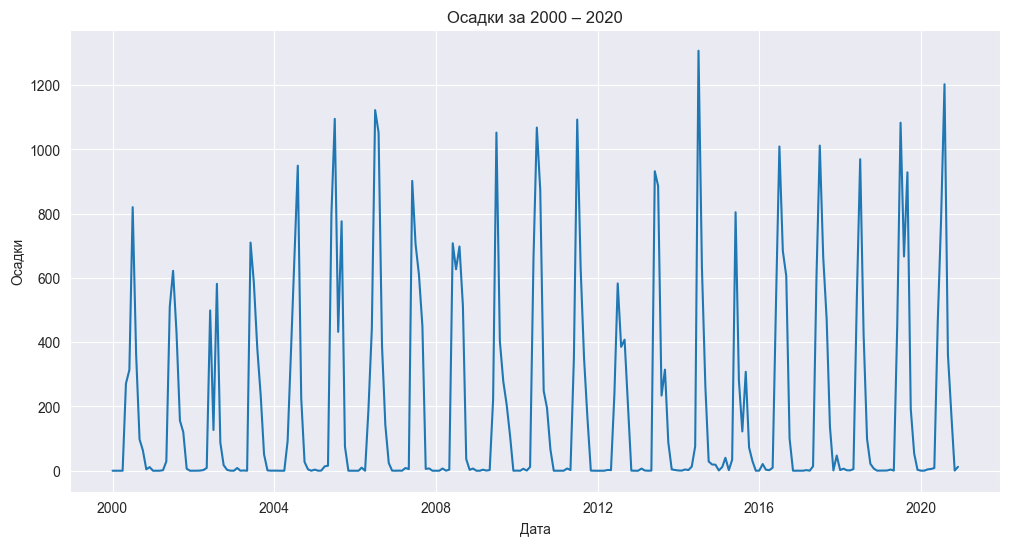

In [19]:
plt.plot(df.index, df["Precipitation"])
plt.title("Осадки за 2000 – 2020")
plt.xlabel("Дата")
plt.ylabel("Осадки")
plt.show()

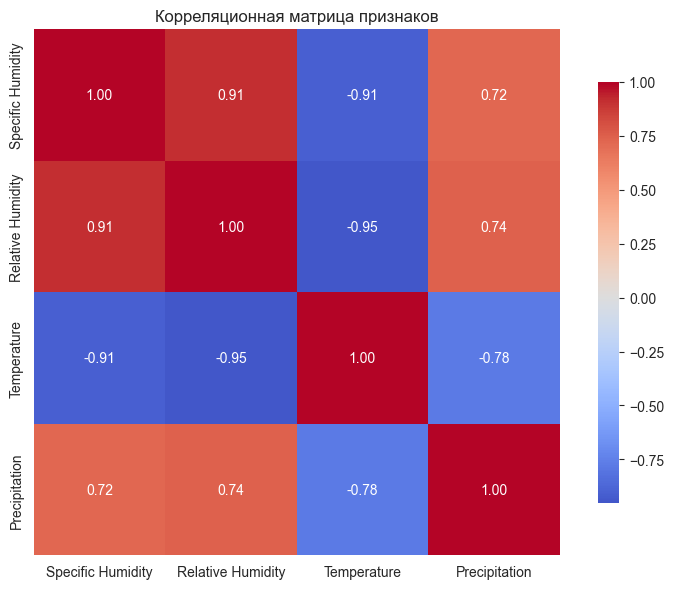

Корреляция с Precipitation:
Precipitation        1.000000
Relative Humidity    0.743112
Specific Humidity    0.724540
Temperature         -0.779399
Name: Precipitation, dtype: float64


In [20]:
# Корреляционная матрица числовых признаков
stolb = ["Specific Humidity", "Relative Humidity", "Temperature", "Precipitation"]
corr = df[stolb].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, cbar_kws={"shrink": 0.8})
plt.title("Корреляционная матрица признаков")
plt.tight_layout()
plt.show()

# Выводы
print("Корреляция с Precipitation:")
print(corr["Precipitation"].sort_values(ascending=False))

In [21]:
# Проверка дубликатов
dup_mask = df.index.duplicated(keep=False)
print(f"Дубликатов по индексу (дате): {dup_mask.sum()}")
print(f"Полных дубликатов строк: {df.duplicated().sum()}")

# Поиск аномалий в Precipitation
q1 = df["Precipitation"].quantile(0.25)
q3 = df["Precipitation"].quantile(0.75)
iqr = q3 - q1
niz = q1 - 1.5 * iqr
verh = q3 + 1.5 * iqr
vne = df[(df["Precipitation"] < niz) | (df["Precipitation"] > verh)]

print(f"\nIQR = {iqr:.2f}; границы: [{niz:.2f}; {verh:.2f}]")
print(f"Аномалий по IQR: {len(vne)}")
print(vne[["Precipitation"]].sort_values("Precipitation", ascending=False).head(10))

# Обработка аномалий (отрицательных осадков)
otr = (df["Precipitation"] < 0).sum()
print(f"\nОтрицательных осадков: {otr}")

# Ограничиваем аномалии 99-ю процентами, чтобы деревья не переобучались на пиках.
df_clean = df.copy()
p99 = df_clean["Precipitation"].quantile(0.99)
df_clean["Precipitation"] = df_clean["Precipitation"].clip(lower=0, upper=p99)
print(f"Верхняя граница клиппинга: {p99:.2f}")

Дубликатов по индексу (дате): 0
Полных дубликатов строк: 0

IQR = 352.80; границы: [-528.79; 882.40]
Аномалий по IQR: 17
            Precipitation
Date                     
2014-07-01        1307.43
2020-08-01        1203.09
2006-07-01        1122.56
2005-07-01        1095.38
2011-07-01        1093.05
2019-07-01        1083.30
2010-07-01        1068.20
2006-08-01        1052.65
2009-07-01        1052.50
2017-07-01        1012.11

Отрицательных осадков: 0
Верхняя граница клиппинга: 1108.70


## 2. Разделение на tren и test

In [22]:
# Обучение на данных до 2017 года, тест с 2017 по 2020
tren_df = df_clean[df_clean.index.year < 2017].copy()
test_df  = df_clean[df_clean.index.year >= 2017].copy()

print(f"Train shape: {tren_df.shape} (с {tren_df.index.min().date()} по {tren_df.index.max().date()})")
print(f"Test shape: {test_df.shape} (с {test_df.index.min().date()} по {test_df.index.max().date()})")

Train shape: (204, 7) (с 2000-01-01 по 2016-12-01)
Test shape: (48, 7) (с 2017-01-01 по 2020-12-01)


## 3. Вспомогательные функции

In [23]:
# Функция рассчета метрик

def compute_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return mae, rmse

In [24]:
# Функция генерации признаков

def create_features(df):
    df = df.copy()
    # Признаки из даты (сезонность)
    df["month"] = df.index.month
    df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
    df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)
    
    # Лаги (предыдущие значения осадков)
    for lag in [1, 2, 3, 6, 12]:
        df[f"lag_{lag}"] = df["Precipitation"].shift(lag)
        
    # Скользящее среднее (тренд)
    df["rolling_mean_3"] = df["Precipitation"].shift(1).rolling(3).mean()
    df["rolling_mean_12"] = df["Precipitation"].shift(1).rolling(12).mean()
    
    return df

# Генерируем признаки на объединённом ряду
full_feat = create_features(df)

# Разделение признаков на tren и test
tren_feat = full_feat.loc[tren_df.index].dropna()
test_feat  = full_feat.loc[test_df.index].dropna()

print(f"Train после генерации: {tren_feat.shape}")
print(f"Test после генерации: {test_feat.shape}")  # должно быть (48, 17)

Train после генерации: (192, 17)
Test после генерации: (48, 17)


## 4. Baseline модель

In [25]:
y_test = test_feat["Precipitation"]
baseline_pred = np.full(shape=len(y_test), fill_value=tren_df["Precipitation"].mean())
mae, rmse = compute_metrics(y_test, baseline_pred)
print(f"Baseline: MAE = {mae:.2f}, RMSE = {rmse:.2f}")

Baseline: MAE = 278.91, RMSE = 353.81


## 5. Модель LinearRegression

In [26]:
from sklearn.linear_model import LinearRegression

# Выбираем все признаки, кроме Precipitation
features = [c for c in tren_feat.columns if c != "Precipitation"]

x_tren = tren_feat[features]
y_tren = tren_feat["Precipitation"]

x_test = test_feat[features]
y_test = test_feat["Precipitation"]

# Обучение
model = LinearRegression()
model.fit(x_tren, y_tren)

# Предсказание
y_pred = model.predict(x_test)

# Метрики
mae_lr = mean_absolute_error(y_test, y_pred)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"LinearRegression: MAE = {mae_lr:.2f}, RMSE = {rmse_lr:.2f}")

LinearRegression: MAE = 122.64, RMSE = 177.70


## 6. Модель LGBMRegressor

In [27]:
from lightgbm import LGBMRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

# Небольшой поиск гиперпараметров по временным фолдам
tscv = TimeSeriesSplit(n_splits=3)
param_grid = {
    "n_estimators": [200, 400],
    "learning_rate": [0.03, 0.1],
    "max_depth": [3, -1],
    "min_child_samples": [5, 20],
}

lgbm_base = LGBMRegressor(random_state=42, verbose=-1)
grid = GridSearchCV(
    lgbm_base, param_grid,
    cv=tscv, scoring="neg_mean_absolute_error", n_jobs=-1
)
grid.fit(x_tren, y_tren)

lgbm = grid.best_estimator_
print("Лучшие параметры LGBM:", grid.best_params_)
print(f"CV MAE (на train-фолдах): {-grid.best_score_:.2f}")

y_pred_lgbm = lgbm.predict(x_test)
mae_lgbm, rmse_lgbm = compute_metrics(y_test, y_pred_lgbm)
print(f"LGBM (tuned): MAE = {mae_lgbm:.2f}, RMSE = {rmse_lgbm:.2f}")

Лучшие параметры LGBM: {'learning_rate': 0.1, 'max_depth': 3, 'min_child_samples': 5, 'n_estimators': 200}
CV MAE (на train-фолдах): 85.94
LGBM (tuned): MAE = 70.12, RMSE = 127.96


In [28]:
# Проверка переобучения: метрики на train для обеих моделей
y_tren_pred_lr   = model.predict(x_tren)
y_tren_pred_lgbm = lgbm.predict(x_tren)

mae_tr_lr,   rmse_tr_lr   = compute_metrics(y_tren, y_tren_pred_lr)
mae_tr_lgbm, rmse_tr_lgbm = compute_metrics(y_tren, y_tren_pred_lgbm)

print(f"LinearRegression  TRAIN: MAE = {mae_tr_lr:.2f},   RMSE = {rmse_tr_lr:.2f}")
print(f"LinearRegression  TEST : MAE = {mae_lr:.2f},   RMSE = {rmse_lr:.2f}")
print()
print(f"LGBM              TRAIN: MAE = {mae_tr_lgbm:.2f},   RMSE = {rmse_tr_lgbm:.2f}")
print(f"LGBM              TEST : MAE = {mae_lgbm:.2f},   RMSE = {rmse_lgbm:.2f}")

LinearRegression  TRAIN: MAE = 108.28,   RMSE = 153.90
LinearRegression  TEST : MAE = 122.64,   RMSE = 177.70

LGBM              TRAIN: MAE = 7.41,   RMSE = 11.02
LGBM              TEST : MAE = 70.12,   RMSE = 127.96


## 7. Визуализация предсказаний

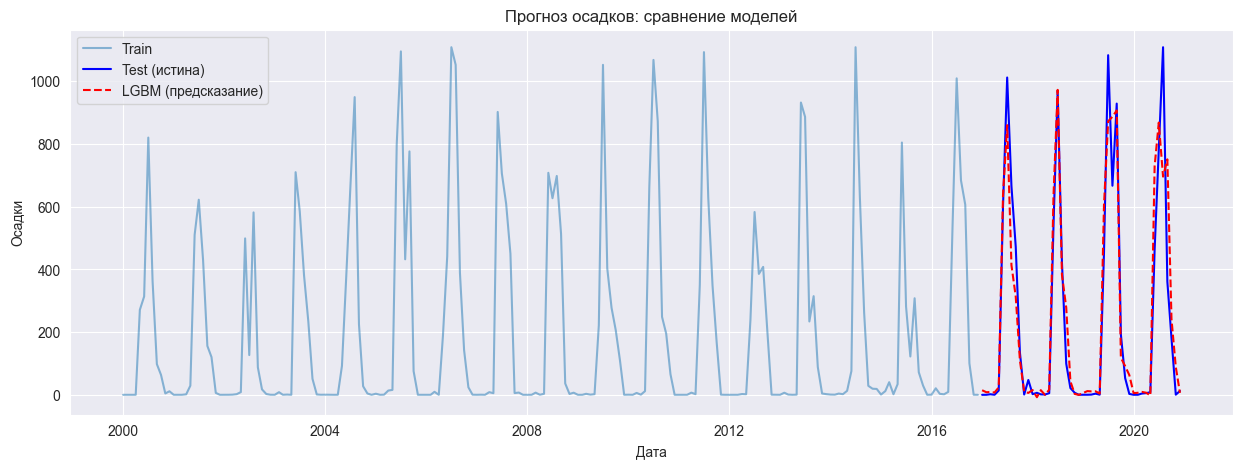

In [29]:
plt.figure(figsize=(15, 5))
plt.plot(tren_df.index, tren_df["Precipitation"], label="Train", alpha=0.5)
plt.plot(test_df.index, test_df["Precipitation"], label="Test (истина)", color="blue")

# На графике покажем предсказания лучшей модели (LGBM или LinearRegression, выберите ту, что лучше)
# Предположим, это LGBM (если хуже — замените y_pred_lgbm на y_pred)
plt.plot(test_feat.index, y_pred_lgbm, label="LGBM (предсказание)", color="red", linestyle="--")

plt.title("Прогноз осадков: сравнение моделей")
plt.xlabel("Дата")
plt.ylabel("Осадки")
plt.legend()
plt.grid(True)
plt.show()

## 8. Сводная таблица метрик

In [30]:
results = pd.DataFrame([
    {"Model": "Baseline (mean)",  "MAE": mae,      "RMSE": rmse},
    {"Model": "LinearRegression", "MAE": mae_lr,   "RMSE": rmse_lr},
    {"Model": "LGBM (tuned)",     "MAE": mae_lgbm, "RMSE": rmse_lgbm},
])
results = results.round(2).sort_values("MAE")
print(results)


              Model     MAE    RMSE
2      LGBM (tuned)   70.12  127.96
1  LinearRegression  122.64  177.70
0   Baseline (mean)  278.91  353.81


## 9. Выводы

Во время выполнения работы были обучены три модели для прогнозирования осадков на тестовом периоде 2017–2020 (48 месяцев):

- Признаки для test генерируются на объединённом ряду train + test, чтобы лаги за январь 2017 брались из декабря 2016.
- Корреляционный анализ показал, что осадки положительно связаны с относительной влажностью (0.74) и удельной влажностью (0.72), отрицательно — с температурой (−0.78).
- Дубликаты отсутствуют, аномалии обработаны клиппингом по 99-му перцентилю.
- Для LGBM выполнен подбор гиперпараметров с TimeSeriesSplit, чтобы избежать утечки из будущего. Лучшие параметры: n_estimators=200, learning_rate=0.1, max_depth=3, min_child_samples=5.
- Была произведена проверка переобучения: LinearRegression: train MAE = 108.28, test MAE = 122.64 — разрыв небольшой, модель устойчива. LGBM: train MAE = 7.41, test MAE = 70.12 — сильное переобучение (train в 9.5 раз лучше test). Это ожидаемо для деревьев на 192 точках; возможно, стоит ещё увеличить min_child_samples или уменьшить n_estimators, но даже в таком виде LGBM лучший на test.
- LGBM показывает наименьшую ошибку (MAE = 70.12) и лучше всех улавливает сезонные пики.
- LinearRegression — простая и интерпретируемая альтернатива.
- Для планирования сброса воды на ГЭС лучшим вариантом будет LGBM, но она всеравновсё равно недооценивает экстремальные ливни из-за клиппинга и сглаживания деревьями